# MTBS meets some HMS data

In [1]:
import os
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [95]:
list_dfs = []
for date in pd.date_range('2019-01-01', '2019-12-31'):
    
    base_url = 'https://satepsanone.nesdis.noaa.gov/pub/FIRE/web/HMS/Fire_Points/Text'
    
    year = date.year
    month = str(date.month).zfill(2)
    url = f"{base_url}/{year}/{month}/hms{date.strftime('%Y%m%d')}.txt"
    
    try:
        data = pd.read_csv(url, skipinitialspace=True)
        data_modis = data[(data['Method of Detect'] == "MODIS") & 
                          (data['Fire RadPower'] != -999.0)]
        list_dfs.append(data_modis)
    except Exception as e: 
        print(f'Not found {e}: {url}')

Not found HTTP Error 404: Not Found: https://satepsanone.nesdis.noaa.gov/pub/FIRE/web/HMS/Fire_Points/Text/2019/02/hms20190225.txt
Not found HTTP Error 404: Not Found: https://satepsanone.nesdis.noaa.gov/pub/FIRE/web/HMS/Fire_Points/Text/2019/07/hms20190709.txt
Not found HTTP Error 404: Not Found: https://satepsanone.nesdis.noaa.gov/pub/FIRE/web/HMS/Fire_Points/Text/2019/07/hms20190710.txt


In [96]:
modis_fire_points = pd.concat(list_dfs)
modis_fire_points = gpd.GeoDataFrame(
    modis_fire_points, geometry=gpd.points_from_xy(modis_fire_points.Lon, modis_fire_points.Lat))
modis_fire_points = modis_fire_points.set_crs('EPSG:4326')

In [23]:
import shapely
us_shape = gpd.read_file('/Users/topcat/Downloads/cb_2018_us_state_20m/cb_2018_us_state_20m.shp')
us_shape = us_shape[~ us_shape.STUSPS.isin(['AK', 'HI', 'PR', 'GU', 'VI', 'MP', 'AS'])]
us_shape[[isinstance(i, shapely.geometry.polygon.Polygon) for i in us_shape.geometry]].dissolve()

GEOSException: IllegalArgumentException: Argument must be Polygonal or LinearRing

In [97]:
fire_shape = gpd.read_file('/Users/topcat/Downloads/mtbs_perimeter_data/mtbs_perims_DD.shp')
fire_shape = fire_shape.assign(
    date = pd.to_datetime(fire_shape['Ig_Date'])
)
fire_shape = fire_shape.to_crs('EPSG:4326')

In [122]:
type(fire_shape)

geopandas.geodataframe.GeoDataFrame

In [150]:
us_shape.explode()

FEATURECLA  SCALERANK  ADM2_CODE ISO_3166_2 ISO_A2  ADM0_SR  \
0    0  Admin-2 scale rank          0  USA-53073      US-53     US        1   
     1  Admin-2 scale rank          0  USA-53073      US-53     US        1   
     2  Admin-2 scale rank          0  USA-53073      US-53     US        1   
1    0  Admin-2 scale rank          0  USA-53047      US-53     US        1   
2    0  Admin-2 scale rank          0  USA-53019      US-53     US        1   
...                    ...        ...        ...        ...    ...      ...   
3185 0  Admin-2 scale rank          0  USA-56043      US-56     US        1   
3186 0  Admin-2 scale rank          0  USA-56013      US-56     US        1   
3187 0  Admin-2 scale rank          0  USA-56025      US-56     US        1   
3188 0  Admin-2 scale rank          0  USA-56017      US-56     US        1   
3189 0  Admin-2 scale rank          0  USA-56035      US-56     US        1   

               NAME            NAME_ALT NAME_LOCAL    TYPE  ...      NAME_PT  \
0    0      Whatcom      Whatcom County       None  County  ...      Whatcom   
     1      Whatcom      Whatcom County       None  County  ...      Whatcom   
     2      Whatcom      Whatcom County       None  County  ...      Whatcom   
1    0     Okanogan     Okanogan County       None  County  ...     Okanogan   
2    0        Ferry        Ferry County       None  County  ...        Ferry   
...             ...                 ...        ...     ...  ...          ...   
3185 0     Washakie     Washakie County       None  County  ...     Washakie   
3186 0      Fremont      Fremont County       None  County  ...      Fremont   
3187 0      Natrona      Natrona County       None  County  ...      Natrona   
3188 0  Hot Springs  Hot Springs County       None  County  ...  Hot Springs   
3189 0     Sublette     Sublette County       None  County  ...     Sublette   

            NAME_RU      NAME_SV      NAME_TR      NAME_UK  \
0    0       Уотком      Whatcom      Whatcom       Вотком   
     1       Уотком      Whatcom      Whatcom       Вотком   
     2       Уотком      Whatcom      Whatcom       Вотком   
1    0     Оканоган     Okanogan     Okanogan     Оканоґан   
2    0        Ферри        Ferry        Ferry        Феррі   
...             ...          ...          ...          ...   
3185 0       Уошэки     Washakie     Washakie      Вошейкі   
3186 0      Фримонт      Fremont      Fremont      Фремонт   
3187 0      Натрона      Natrona      Natrona      Натрона   
3188 0  Хот-Спрингс  Hot Springs  Hot Springs  Гот-Спрінґс   
3189 0      Саблетт     Sublette     Sublette      Саблетт   

                            NAME_UR      NAME_VI  NAME_ZH  NAME_ZHT  \
0    0        واٹکم کاؤنٹی، واشنگٹن      Whatcom    霍特科姆县     霍特科姆縣   
     1        واٹکم کاؤنٹی، واشنگٹن      Whatcom    霍特科姆县     霍特科姆縣   
     2        واٹکم کاؤنٹی، واشنگٹن      Whatcom    霍特科姆县     霍特科姆縣   
1    0     اوکاناگن کاؤنٹی، واشنگٹن     Okanogan    奥卡诺根县     奧卡諾根縣   
2    0         فیری کاؤنٹی، واشنگٹن        Ferry      费里县       費里縣   
...                             ...          ...      ...       ...   
3185 0      واشیکی کاؤنٹی، وائیومنگ     Washakie     华谢基县      華謝基縣   
3186 0     فریمونٹ کاؤنٹی، وائیومنگ      Fremont    弗里蒙特县     弗里蒙特郡   
3187 0     نیٹرونا کاؤنٹی، وائیومنگ      Natrona    纳特罗纳县     納特羅納縣   
3188 0  ہاٹ سپرنگز کاؤنٹی، وائیومنگ  Hot Springs      温泉县       溫泉郡   
3189 0       سبلیٹ کاؤنٹی، وائیومنگ     Sublette    萨布莱特县     薩布萊特郡   

                                                 geometry  
0    0  POLYGON ((-122.75302 48.99251, -122.65326 48.9...  
     1  POLYGON ((-123.09051 48.99251, -123.03531 48.9...  
     2  POLYGON ((-122.62141 48.66852, -122.61535 48.6...  
1    0  POLYGON ((-120.85196 48.99251, -120.67495 48.9...  
2    0  POLYGON ((-118.83688 48.99251, -118.69668 48.9...  
...                                                   ...  
3185 0  POLYGON ((-108.55055 44.16845, -108.19008 44.1...  
3186 0  POLYGON ((-107.52291

<AxesSubplot:>

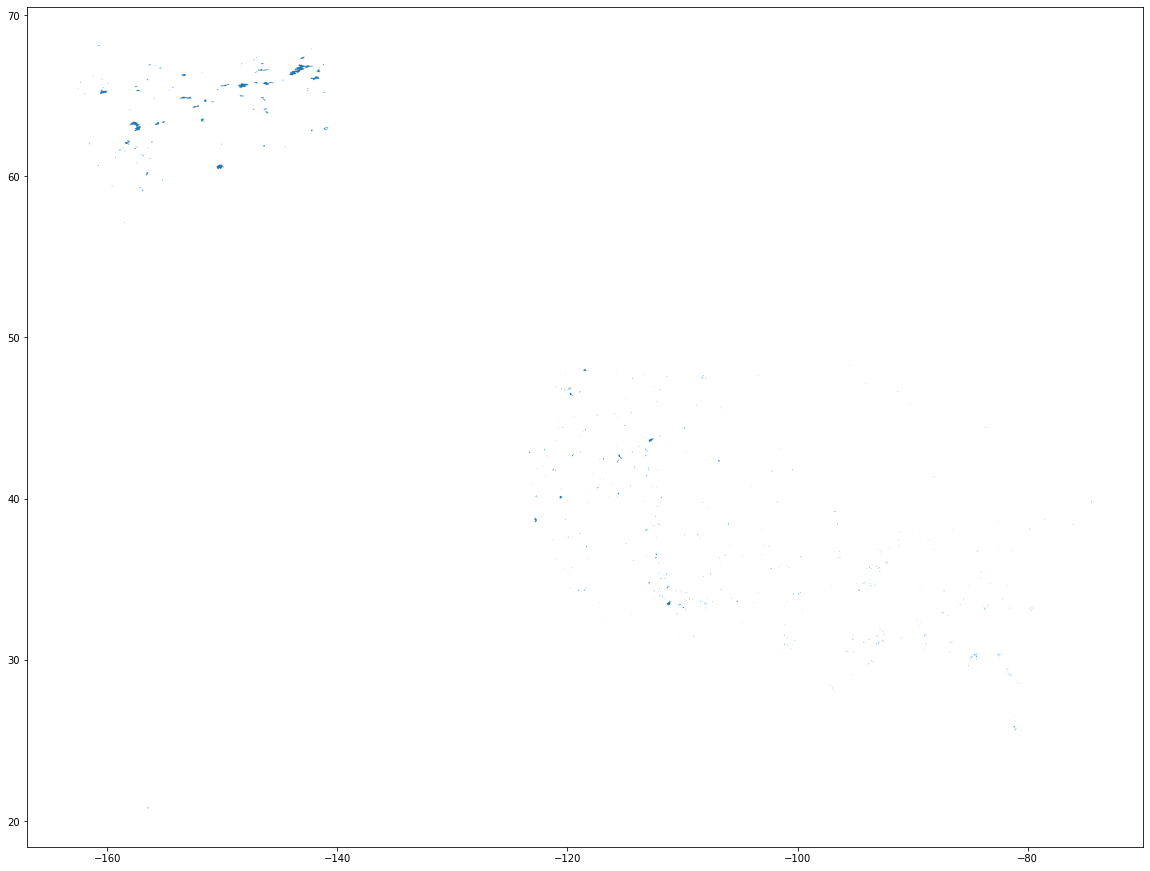

In [108]:
fig, ax = plt.subplots(figsize = (20, 20))
fire_shape[fire_shape.date.dt.year == 2019].plot(ax=ax)
#modis_fire_points.plot(ax=ax, color='red', markersize=0.5, marker=".")